# 03 - Service-time groups: clustering, then classification

The scheduling model (notebook 04) needs, for each patient, how long the consultation will take. The data give `service_time` = `dtc` - `dts`, the delay in **days** between the scheduling of the consultation and its completion (Feyman et al., 2022); they do not give a length in minutes. The approach is in two steps:

1. **Clustering**: the consultations of the train set are split into two groups, *short* and *long* `service_time`, by exact K-medians (section 2).
2. **Classification**: the group of a consultation is predicted when the appointment is booked, from the same 14 predictors as the no-show, with the same four models, grids, pipeline and metrics as notebook 02 (section 3).

In notebook 04 each group gets a consultation length in minutes, set there as a parameter.

## Outline
- [0 - Parameters](#0)
- [1 - Data and split](#1)
- [2 - Clustering of service_time](#2)
- [3 - Models](#3): [Random Forest](#3.1), [XGBoost](#3.2), [AdaBoost](#3.3), [MLP](#3.4)
- [4 - Comparison of the models and export](#4)

In [1]:
import sys
sys.path.insert(0, "..")          # utils_ml.py is at the root of the repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
import xgboost as xgb
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from utils_ml import *

<a name="0"></a>
## 0 - Parameters

Every choice of this notebook is set in the cell below, with its reason. The training choices are those of notebook 02, so that both predictions are made the same way.

In [2]:
DATA_PATH = "../data/data_prep.parquet"      # written by 01_data_preparation.ipynb
SPLIT_PATH = "../runs/pilot_split.parquet"         # train / validation / test of notebook 02: the same consultations
GROUPS_PATH = "../runs/pilot_test_groups.parquet"  # predicted and true group of the test consultations, read by notebook 04
SERVICE_TIME = "service_time"                # dtc - dts, in days: clustered, never a predictor
NOT_PREDICTORS = ["NoShow", SERVICE_TIME]
RANDOM_STATE = 0

# Trained models are saved here (not versioned: large) and loaded instead of trained when the
# notebook is run again, for a quick restart and to reproduce the results with the same models.
MODELS_DIR = "../runs/pilot_models/service_time_groups"
RETRAIN = False                               # True: train again even if a saved model exists

N_CHECK = 2_000                               # values on which the K-medians is checked against a plain search

# Same choices as notebook 02 (target encoding, grids, scoring, threshold, MLP).
CATEGORICAL = ["sta3n", "stopcode", "zip", "state"]
TARGET_ENCODER = dict(target_type="binary", smooth="auto", cv=5, shuffle=True, random_state=RANDOM_STATE)
CV_FOLDS = 3
SCORING = "f1_macro"
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)
GRID_RF = {"n_estimators": [100], "max_depth": [10, 15, 20], "min_samples_split": [2, 5],
           "min_samples_leaf": [2, 4], "max_features": ["sqrt"], "class_weight": ["balanced"]}
GRID_XGB = {"n_estimators": [1000], "max_depth": [20, 25], "min_child_weight": [2], "gamma": [0.3],
            "subsample": [0.4], "reg_alpha": [0.2], "learning_rate": [0.01, 0.1]}
GRID_ADA = {"n_estimators": [100], "learning_rate": [0.05, 0.1]}
MLP_PARAMS = dict(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam", alpha=1e-4,
                  batch_size=256, max_iter=50, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=10, random_state=RANDOM_STATE)
# Unlike the no-shows (3 %), neither group is rare (see section 2): no SMOTE. XGBoost gets the same
# weighting as in notebook 02, short / long in the train set (computed in section 2).
SMOTE_RATIO = None
PERMUTATION_ROWS = 200_000

<a name="1"></a>
## 1 - Data and split

The consultations and their train / validation / test part are those of notebook 02.

In [3]:
split = pd.read_parquet(SPLIT_PATH)["part"]
data = pd.read_parquet(DATA_PATH).loc[split.index]
FEATURES = CATEGORICAL + [c for c in data.columns if c not in CATEGORICAL + NOT_PREDICTORS]
rows = {part: split.index[split == part] for part in ["train", "validation", "test"]}
print(f"{len(data):,} consultations: " + ", ".join(f"{p} {len(r):,}" for p, r in rows.items()))
print(f"{len(FEATURES)} predictors: {FEATURES}")
data[SERVICE_TIME].describe()

1,134,261 consultations: train 674,884, validation 119,098, test 340,279
14 predictors: ['sta3n', 'stopcode', 'zip', 'state', 'dta', 'dts', 'non_va', 'typecare', 'day_of_week', 'day_of_month', 'month', 'hour', 'prior_noShow_rate', 'prior_service_time_avg']


count    1.134261e+06
mean     2.206617e+01
std      2.534765e+01
min      0.000000e+00
25%      6.000000e+00
50%      1.400000e+01
75%      3.000000e+01
max      3.650000e+02
Name: service_time, dtype: float64

<a name="2"></a>
## 2 - Clustering of service_time

Exact K-medians with two groups (`kmedians_two_groups`): every cutoff between two distinct values is tried, and the one minimising the sum of absolute deviations to the median of each group is kept. With one variable this is the exact optimum. The median is used rather than the mean because `service_time` is very skewed (a few delays of almost a year). The cutoff is computed on the **train** set only.

In [4]:
groups = kmedians_two_groups(data.loc[rows["train"], SERVICE_TIME])
CUTOFF = groups["cutoff"]
print(f"Cutoff: short <= {CUTOFF:g} days < long")
print(f"Median of each group: short {groups['median_short']:g} days, long {groups['median_long']:g} days")
print(f"Share of the long group (train): {groups['share_long']:.4f}")

# Check: on N_CHECK values, the same cost as trying every cutoff with np.median directly.
sample = data.loc[rows["train"], SERVICE_TIME].sample(N_CHECK, random_state=RANDOM_STATE).to_numpy(dtype=float)
plain = min(np.abs(a - np.median(a)).sum() + np.abs(b - np.median(b)).sum()
            for c in np.unique(sample)[:-1] for a, b in [(sample[sample <= c], sample[sample > c])])
print(f"Check on {N_CHECK:,} values: K-medians cost {kmedians_two_groups(sample)['cost']:.4f}, "
      f"plain search {plain:.4f}")

Cutoff: short <= 22 days < long
Median of each group: short 7 days, long 38 days
Share of the long group (train): 0.3468


Check on 2,000 values: K-medians cost 20282.0000, plain search 20282.0000


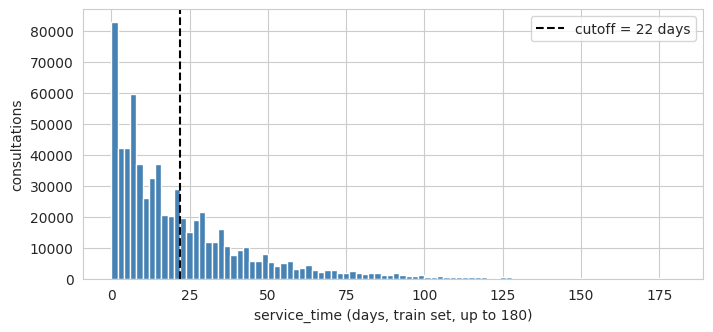

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
short,440854.0,8.630524,6.652134,0.0,3.0,7.0,14.0,22.0
long,234030.0,47.446092,28.170774,23.0,29.0,38.0,56.0,365.0


In [5]:
data["group"] = (data[SERVICE_TIME] > CUTOFF).astype(int)        # 0 = short, 1 = long
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(data.loc[rows["train"], SERVICE_TIME], bins=np.arange(0, 181, 2), color="steelblue")
ax.axvline(CUTOFF, color="black", ls="--", label=f"cutoff = {CUTOFF:g} days")
ax.set_xlabel("service_time (days, train set, up to 180)"); ax.set_ylabel("consultations"); ax.legend()
plt.show()
data.loc[rows["train"]].groupby("group")[SERVICE_TIME].describe().rename(index={0: "short", 1: "long"})

In [6]:
X_train, y_train = data.loc[rows["train"], FEATURES], data.loc[rows["train"], "group"].to_numpy()
X_val, y_val = data.loc[rows["validation"], FEATURES], data.loc[rows["validation"], "group"].to_numpy()
X_test, y_test = data.loc[rows["test"], FEATURES], data.loc[rows["test"], "group"].to_numpy()
XGB_SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()   # short / long, as for the no-shows
print(f"Share of the long group: train {y_train.mean():.4f}, validation {y_val.mean():.4f}, test {y_test.mean():.4f}")
print(f"XGBoost scale_pos_weight = {XGB_SCALE_POS_WEIGHT:.4f}")

Share of the long group: train 0.3468, validation 0.3467, test 0.3461
XGBoost scale_pos_weight = 1.8837


<a name="3"></a>
## 3 - Models

Same pipeline as notebook 02 (`make_pipeline`: target encoder, StandardScaler, model; no SMOTE here), same grid search (`train_model`), same evaluation (`evaluate_classifier`): threshold chosen on the validation set, metrics of the paper on train and test, ROC curve, errors and feature importances. Class 1 is the long group.

In [7]:
models, probas, thresholds, results = {}, {}, {}, {}

def run(name, model, grid):
    pipeline = make_pipeline(model, CATEGORICAL, TARGET_ENCODER, SMOTE_RATIO, RANDOM_STATE)
    models[name], cv, minutes, loaded = train_model(pipeline, grid, X_train, y_train, SCORING, CV_FOLDS, RANDOM_STATE,
                                                    f"{MODELS_DIR}/{name}.joblib", RETRAIN)
    print(f"{name}: loaded from {MODELS_DIR} (trained in {minutes:.1f} min)" if loaded else f"{name}: trained in {minutes:.1f} min")
    if cv is not None:
        print("Best hyperparameters:", cv.iloc[0]["params"])
        display(cv)
    probas[name] = {part: models[name].predict_proba(X)[:, 1]
                    for part, X in [("train", X_train), ("val", X_val), ("test", X_test)]}

def evaluate(name):
    thresholds[name], results[name] = evaluate_classifier(
        name, models[name], probas[name], y_train, y_val, y_test, X_test, THRESHOLDS,
        FEATURES, PERMUTATION_ROWS, RANDOM_STATE)
    display(results[name].round(4))

<a name="3.1"></a>
### 3.1 - Random Forest

Random Forest: trained in 34.2 min
Best hyperparameters: {'class_weight': 'balanced', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}


,params,mean_test_score,std_test_score,mean_fit_time
9,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.628056,0.001279,61.708455
10,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.627914,0.000965,60.105579
11,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.627914,0.000965,60.160839
8,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.627828,0.001638,63.307401
5,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.618734,0.000917,52.252327
4,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.618313,0.001777,52.043218
7,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.618153,0.001844,51.910417
6,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.618153,0.001844,51.975060
2,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.606174,0.001449,39.503950
3,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.606174,0.001449,39.697657


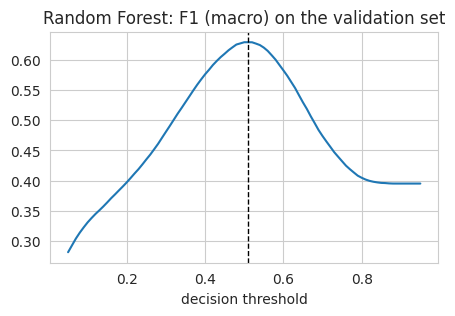

Threshold chosen on the validation set: 0.51


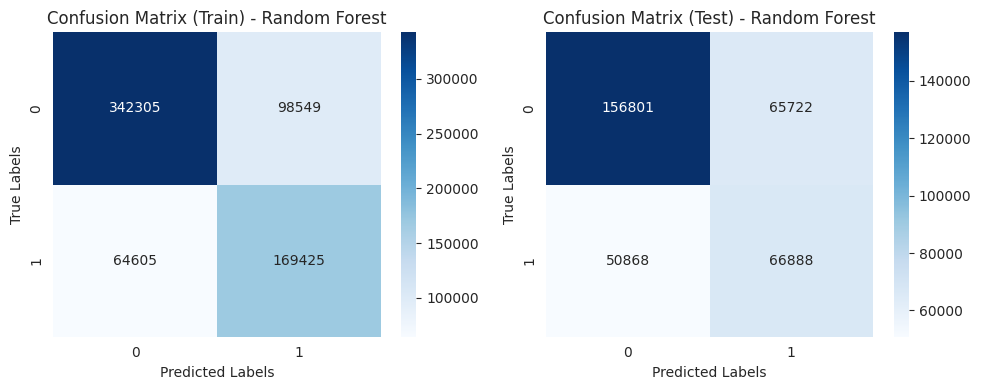

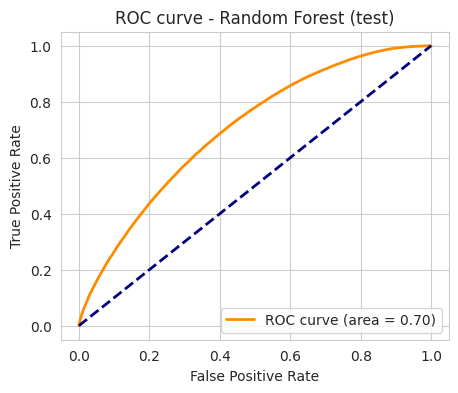

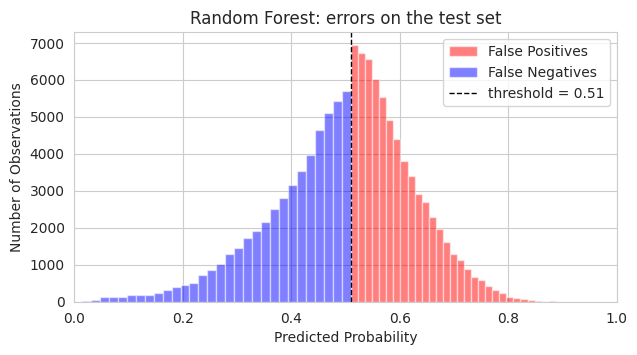

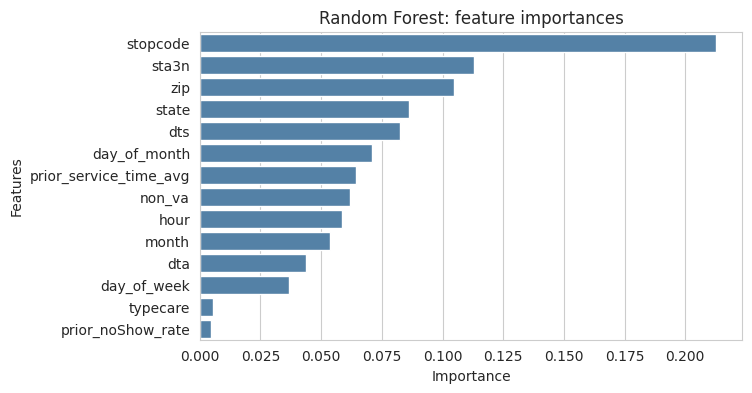

,Train,Test
Metric,,
Recall,0.7502,0.6363
AUC,0.8350,0.7004
Accuracy,0.7582,0.6574
Precision,0.7367,0.6297
F1 Score,0.7413,0.6317


In [8]:
run("Random Forest", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE), GRID_RF)
evaluate("Random Forest")

<a name="3.2"></a>
### 3.2 - XGBoost

XGBoost: trained in 78.6 min
Best hyperparameters: {'gamma': 0.3, 'learning_rate': 0.01, 'max_depth': 20, 'min_child_weight': 2, 'n_estimators': 1000, 'reg_alpha': 0.2, 'subsample': 0.4}


,params,mean_test_score,std_test_score,mean_fit_time
0,"{'gamma': 0.3, 'learning_rate': 0.01, 'max_dep...",0.630970,0.001882,396.259588
1,"{'gamma': 0.3, 'learning_rate': 0.01, 'max_dep...",0.627378,0.001973,498.965220
2,"{'gamma': 0.3, 'learning_rate': 0.1, 'max_dept...",0.605185,0.001935,183.671777
3,"{'gamma': 0.3, 'learning_rate': 0.1, 'max_dept...",0.605077,0.001913,202.189300


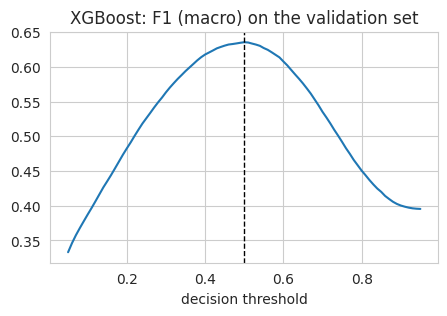

Threshold chosen on the validation set: 0.5


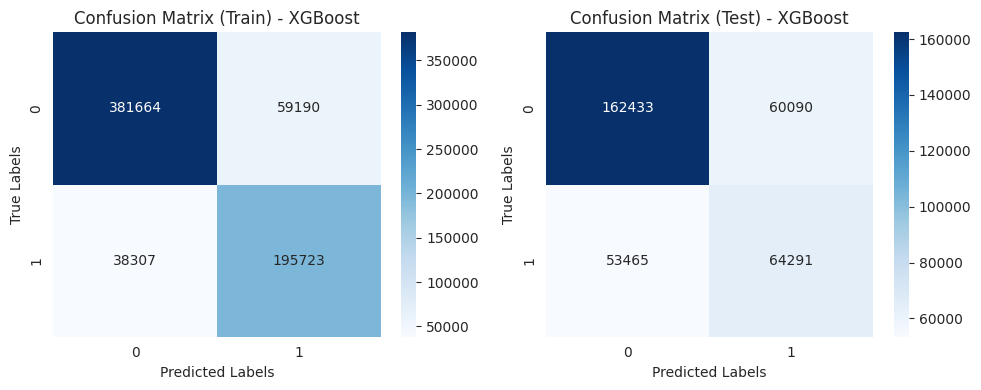

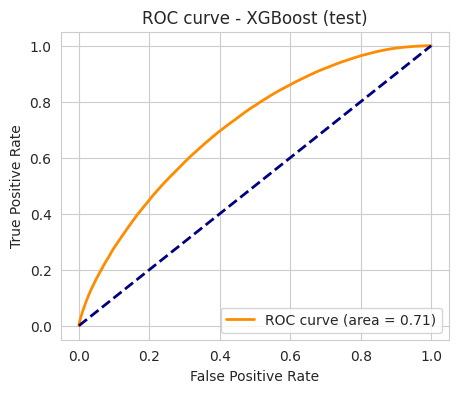

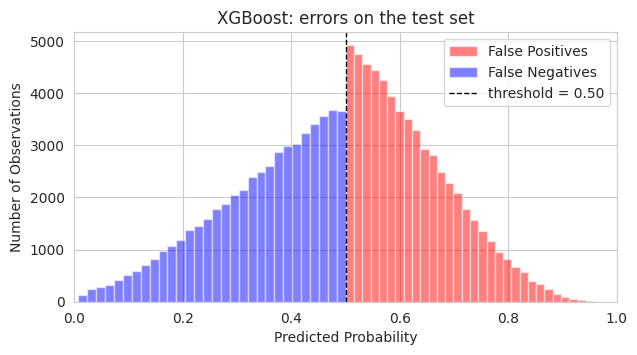

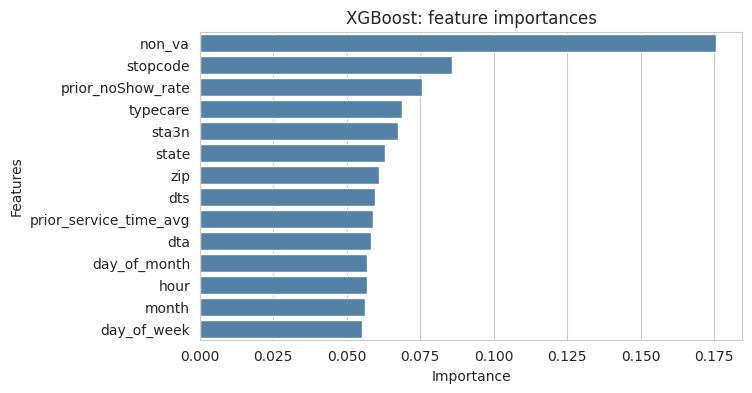

,Train,Test
Metric,,
Recall,0.8510,0.6380
AUC,0.9306,0.7067
Accuracy,0.8555,0.6663
Precision,0.8383,0.6346
F1 Score,0.8437,0.6360


In [9]:
run("XGBoost", xgb.XGBClassifier(objective="binary:logistic", scale_pos_weight=XGB_SCALE_POS_WEIGHT,
                                 tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), GRID_XGB)
evaluate("XGBoost")

<a name="3.3"></a>
### 3.3 - AdaBoost

AdaBoost: trained in 15.9 min
Best hyperparameters: {'learning_rate': 0.05, 'n_estimators': 100}


,params,mean_test_score,std_test_score,mean_fit_time
0,"{'learning_rate': 0.05, 'n_estimators': 100}",0.395123,2.658651e-07,121.267365
1,"{'learning_rate': 0.1, 'n_estimators': 100}",0.395123,2.658651e-07,121.552922


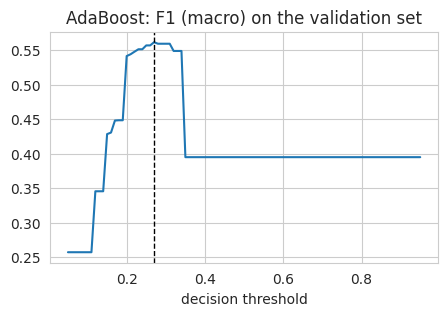

Threshold chosen on the validation set: 0.27


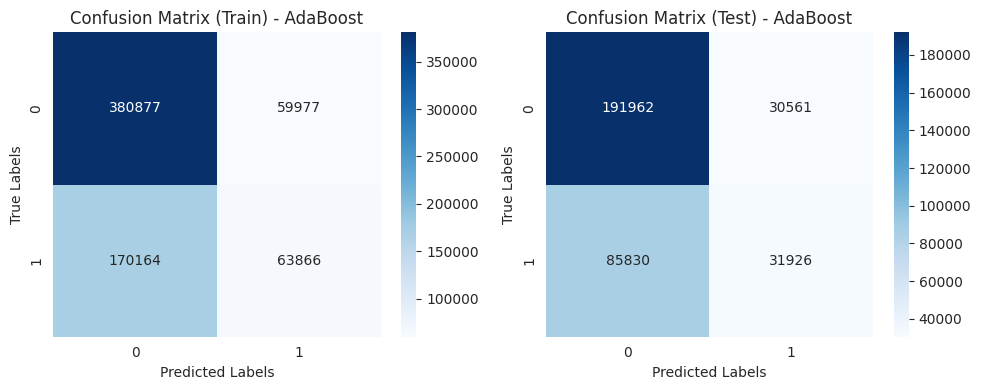

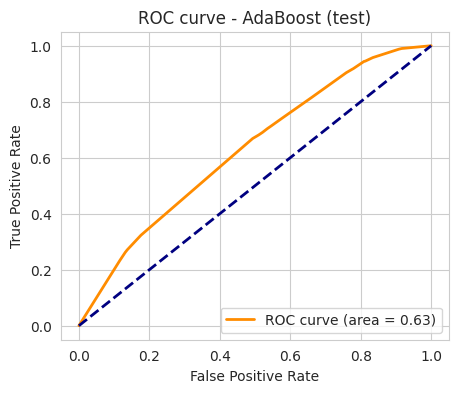

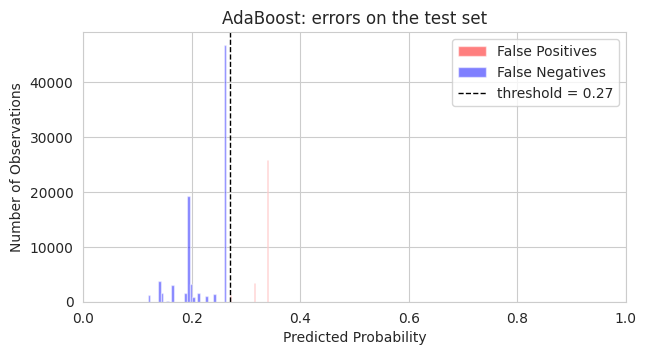

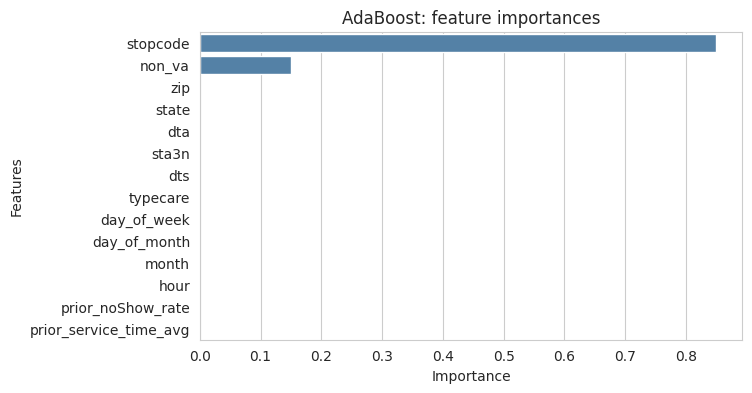

,Train,Test
Metric,,
Recall,0.5684,0.5669
AUC,0.6321,0.6296
Accuracy,0.6590,0.6580
Precision,0.6034,0.6010
F1 Score,0.5624,0.5608


In [10]:
run("AdaBoost", AdaBoostClassifier(random_state=RANDOM_STATE), GRID_ADA)
evaluate("AdaBoost")

<a name="3.4"></a>
### 3.4 - MLP

MLP: trained in 3.8 min


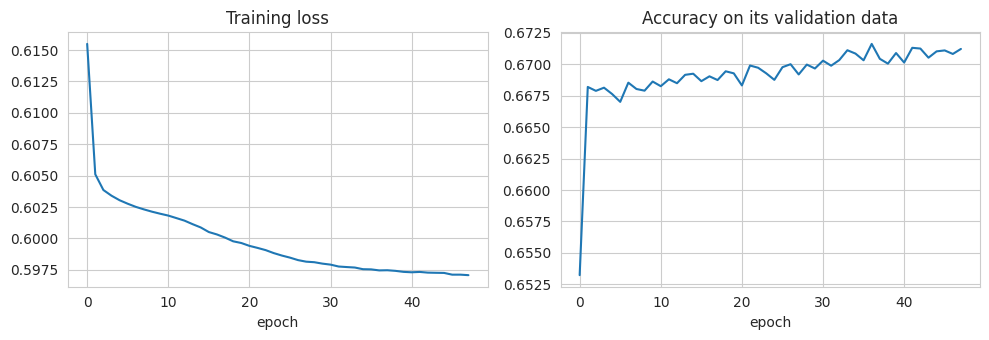

Stopped after 48 epochs


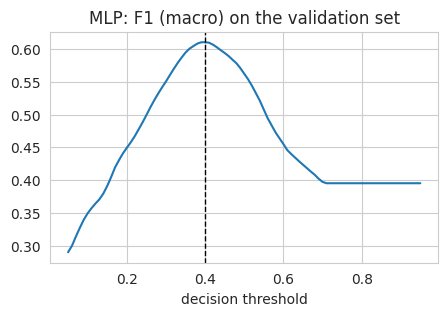

Threshold chosen on the validation set: 0.4


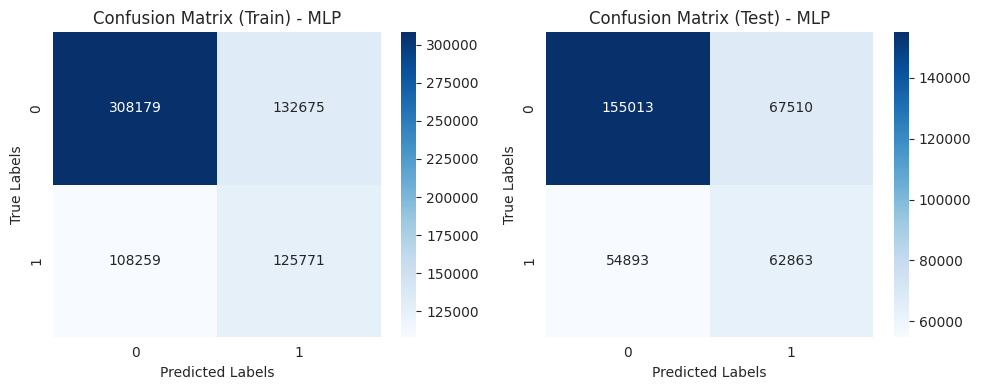

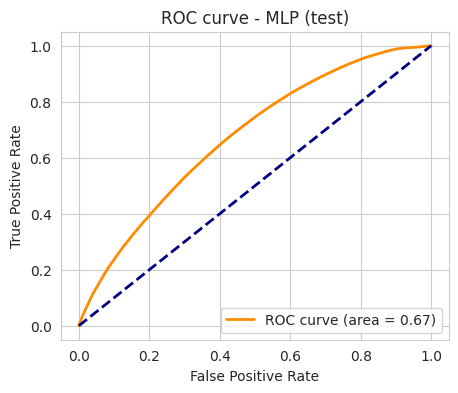

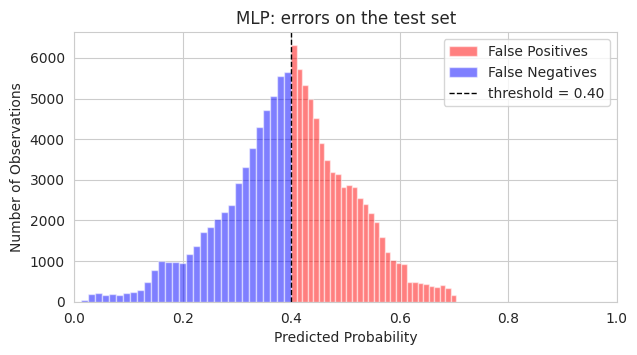

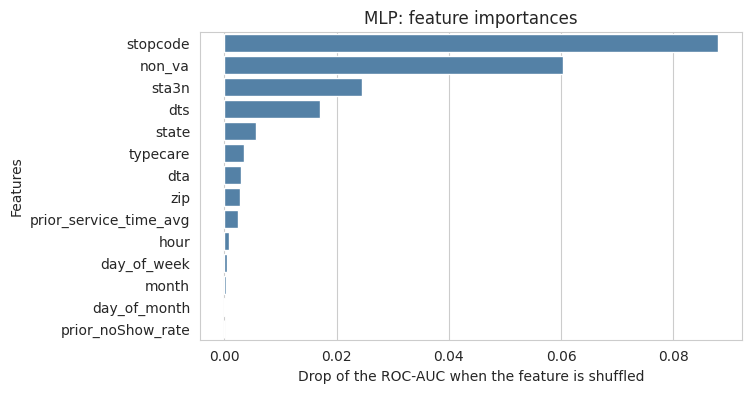

,Train,Test
Metric,,
Recall,0.6182,0.6152
AUC,0.6789,0.6741
Accuracy,0.6430,0.6403
Precision,0.6133,0.6103
F1 Score,0.6149,0.6118


In [11]:
run("MLP", MLPClassifier(**MLP_PARAMS), None)
mlp = models["MLP"].named_steps["model"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(mlp.loss_curve_); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(mlp.validation_scores_); ax[1].set_title("Accuracy on its validation data"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print(f"Stopped after {mlp.n_iter_} epochs")
evaluate("MLP")

<a name="4"></a>
## 4 - Comparison of the models and export

Test metrics of the four models. The model used for the scheduling is the one with the best F1 score on the **validation** set.

In [12]:
test_metrics = pd.DataFrame({name: res["Test"] for name, res in results.items()})
test_metrics.loc["Threshold"] = pd.Series(thresholds)
display(test_metrics.round(4))
val_f1 = pd.Series({name: f1_score(y_val, (probas[name]["val"] >= thresholds[name]).astype(int), average="macro")
                    for name in models})
print("F1 (macro) on the validation set:"); print(val_f1.round(4).to_string())
BEST = val_f1.idxmax()
print(f"\nModel used for the scheduling: {BEST}")

,Random Forest,XGBoost,AdaBoost,MLP
Metric,,,,
Recall,0.6363,0.6380,0.5669,0.6152
AUC,0.7004,0.7067,0.6296,0.6741
Accuracy,0.6574,0.6663,0.6580,0.6403
Precision,0.6297,0.6346,0.6010,0.6103
F1 Score,0.6317,0.6360,0.5608,0.6118
Threshold,0.5100,0.5000,0.2700,0.4000


F1 (macro) on the validation set:
Random Forest    0.6290
XGBoost          0.6357
AdaBoost         0.5616
MLP              0.6106

Model used for the scheduling: XGBoost


Export, for every consultation of the test set (its row in `data_prep.parquet`): the predicted group (used to plan) and the true group (used to judge the real days in notebook 04).

In [13]:
test_groups = pd.DataFrame({"row": rows["test"],
                            "group_pred": (probas[BEST]["test"] >= thresholds[BEST]).astype(int),
                            "group_true": y_test})
test_groups.to_parquet(GROUPS_PATH, index=False)
print(f"Saved {GROUPS_PATH}: {len(test_groups):,} test consultations, model {BEST}")
pd.crosstab(test_groups["group_true"], test_groups["group_pred"], rownames=["true group"], colnames=["predicted group"])

Saved ../runs/pilot_test_groups.parquet: 340,279 test consultations, model XGBoost


predicted group,0,1
true group,,
0,162433,60090
1,53465,64291
